# Math 316 HW3 — Problem 4


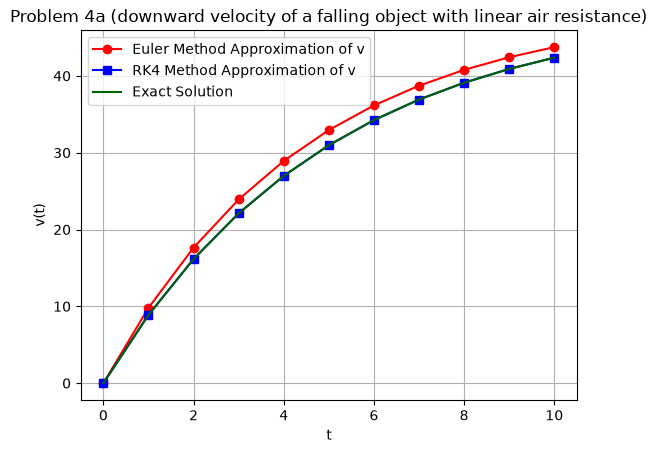

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --------
# Part (a)
# --------

# Our given differential equation in part (a):
# v' = 9.8 -0.2v
def f(t, v):
    return 9.8 - 0.2 * v


# Our given exact solution in part (a):
# v = 49(1 - e^(-0.2t))
def exactSolution(t):
    return 49 * (1 - np.exp(-0.2 * t))


# Euler's method
def eulerMethod(h):
    
    # Our t-values: 0, h, 2h, ... , 10
    t = np.arange(0, 10 + h, h)
    
    vEuler = np.zeros(len(t))
    vEuler[0] = 0

    for i in range(len(t) - 1):
        vEuler[i + 1] = vEuler[i] + h * f(t[i], vEuler[i])
        
    return t, vEuler


# Fourth-order Runge-Kutta method
def rk4Method(h):
    
    # Our t-values: 0, h, 2h, ... , 10
    t = np.arange(0, 10 + h, h)
    
    vRK4 = np.zeros(len(t))
    vRK4[0] = 0

    for i in range(len(t) - 1):
        
        k1 = f(t[i], vRK4[i])
        
        k2 = f(t[i] + (h / 2), vRK4[i] + (h * k1 / 2))
        
        k3 = f(t[i] + (h / 2), vRK4[i] + (h * k2 / 2))
        
        k4 = f(t[i] + h, vRK4[i] + (h * k3))
        
        vRK4[i + 1] = (
            vRK4[i]
            + (h / 6) * (k1 + (2 * k2) + (2 * k3) + k4)
        )
        
    return t, vRK4


# Our step size for part (a)
h = 1


# Euler's method with h = 1
t, vEuler = eulerMethod(h)


# Fourth-order Runge-Kutta method with h = 1
t, vRK4 = rk4Method(h)


# Exact solution
vExact = exactSolution(t)


# Our plots for part (a)

plt.plot(t, vEuler, "o-", color="red", label="Euler Method Approximation of v")
plt.plot(t, vRK4, "s-", color="blue", label="RK4 Method Approximation of v")
plt.plot(t, vExact, color="darkgreen", label="Exact Solution")

plt.xlabel("t")
plt.ylabel("v(t)")
plt.title("Problem 4a (downward velocity of a falling object with linear air resistance)")

plt.legend()
plt.grid()

plt.show()


In [2]:
# --------------------------------------------------------------
# Part (b) (Remark: table for part (b) will be printed terminal)
# --------------------------------------------------------------

# Our results with h = 1
t1, vEuler1 = eulerMethod(1)
t1, vRK41 = rk4Method(1)


# Our results with h = 0.5
t05, vEuler05 = eulerMethod(0.5)
t05, vRK405 = rk4Method(0.5)


# Exact value of v(10)
vExact10 = exactSolution(10)


# Our approximations to v(10)
vEuler1At10 = vEuler1[-1]
vRK41At10 = vRK41[-1]

vEuler05At10 = vEuler05[-1]
vRK405At10 = vRK405[-1]


# Our absolute errors
euler1Error = abs(vEuler1At10 - vExact10)
rk41Error = abs(vRK41At10 - vExact10)

euler05Error = abs(vEuler05At10 - vExact10)
rk405Error = abs(vRK405At10 - vExact10)


# Our table for part (b)

print()
print("Part (b) results")
print("-" * 65)

print(
    f"{'Method':<15}"
    f"{'h':<10}"
    f"{'Approximation v(10)':<22}"
    f"{'Absolute Error':<15}"
)

print("-" * 65)

print(
    f"{'Euler':<15}"
    f"{1:<10}"
    f"{vEuler1At10:<22.8f}"
    f"{euler1Error:<15.8f}"
)

print(
    f"{'Euler':<15}"
    f"{0.5:<10}"
    f"{vEuler05At10:<22.8f}"
    f"{euler05Error:<15.8f}"
)

print(
    f"{'RK4':<15}"
    f"{1:<10}"
    f"{vRK41At10:<22.8f}"
    f"{rk41Error:<15.8f}"
)

print(
    f"{'RK4':<15}"
    f"{0.5:<10}"
    f"{vRK405At10:<22.8f}"
    f"{rk405Error:<15.8f}"
)



Part (b) results
-----------------------------------------------------------------
Method         h         Approximation v(10)   Absolute Error 
-----------------------------------------------------------------
Euler          1         43.73866506           1.37009394     
Euler          0.5       43.04274393           0.67417280     
RK4            1         42.36836213           0.00020899     
RK4            0.5       42.36855911           0.00001201     


In [ ]:
# ------------------------------------------------------
# Part (c) (Remark: a table will be printed in terminal)
# ------------------------------------------------------

# Our error ratios E(1) / E(0.5)

eulerErrorRatio = euler1Error / euler05Error
rk4ErrorRatio = rk41Error / rk405Error


# Our table for part (c)

print()
print("Part (c) results")
print("-" * 70)

print(
    f"{'Method':<15}"
    f"{'E(1)':<18}"
    f"{'E(0.5)':<18}"
    f"{'E(1) / E(0.5)':<18}"
)

print("-" * 70)

print(
    f"{'Euler':<15}"
    f"{euler1Error:<18.8f}"
    f"{euler05Error:<18.8f}"
    f"{eulerErrorRatio:<18.8f}"
)

print(
    f"{'RK4':<15}"
    f"{rk41Error:<18.8f}"
    f"{rk405Error:<18.8f}"
    f"{rk4ErrorRatio:<18.8f}"
)

# Remark: ChatGPT was utilized to convert to .ipynb file and to look up what modules I needed to import.



Part (c) results
----------------------------------------------------------------------
Method         E(1)              E(0.5)            E(1) / E(0.5)     
----------------------------------------------------------------------
Euler          1.37009394        0.67417280        2.03225929        
RK4            0.00020899        0.00001201        17.39580643       
